Тема 2. Моделирование связи частотного и классического определения вероятности

Приведите пример, показывающий связь частотного и классического определения вероятности с помощью моделирования (на примере задачи про красно-синие шары или задачи о сумме очков на двух кубиках). Графически показать стремление частотной вероятности к классической при увеличении числа опытов.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb

# 1. Классический расчет
aces = 4
non_aces = 48
draw_size = 5
target_aces = 2

favorable = comb(aces, target_aces) * comb(non_aces, draw_size - target_aces)
total = comb(aces + non_aces, draw_size)
p_classic = favorable / total

print(f"Классическая вероятность: {favorable}/{total} = {p_classic:.6f}")

# 2. Моделирование (Монте-Карло) - ИСПРАВЛЕННАЯ ВЕРСИЯ
deck = ['A'] * aces + ['N'] * non_aces

N_max = 100000  # Увеличиваем число испытаний для лучшей сходимости

# Создаем массив результатов всех испытаний
results = np.zeros(N_max)
for i in range(N_max):
    draw = np.random.choice(deck, size=draw_size, replace=False)
    if list(draw).count('A') == target_aces:
        results[i] = 1

# Вычисляем накопительную частоту
cumulative_successes = np.cumsum(results)
N_values = np.arange(1, N_max + 1)
empirical_probs = cumulative_successes / N_values

print(f"Частотная вероятность после {N_max} испытаний: {empirical_probs[-1]:.6f}")
print(f"Абсолютная погрешность: {abs(empirical_probs[-1] - p_classic):.6f}")

Классическая вероятность: 103776/2598960 = 0.039930
Частотная вероятность после 100000 испытаний: 0.040890
Абсолютная погрешность: 0.000960


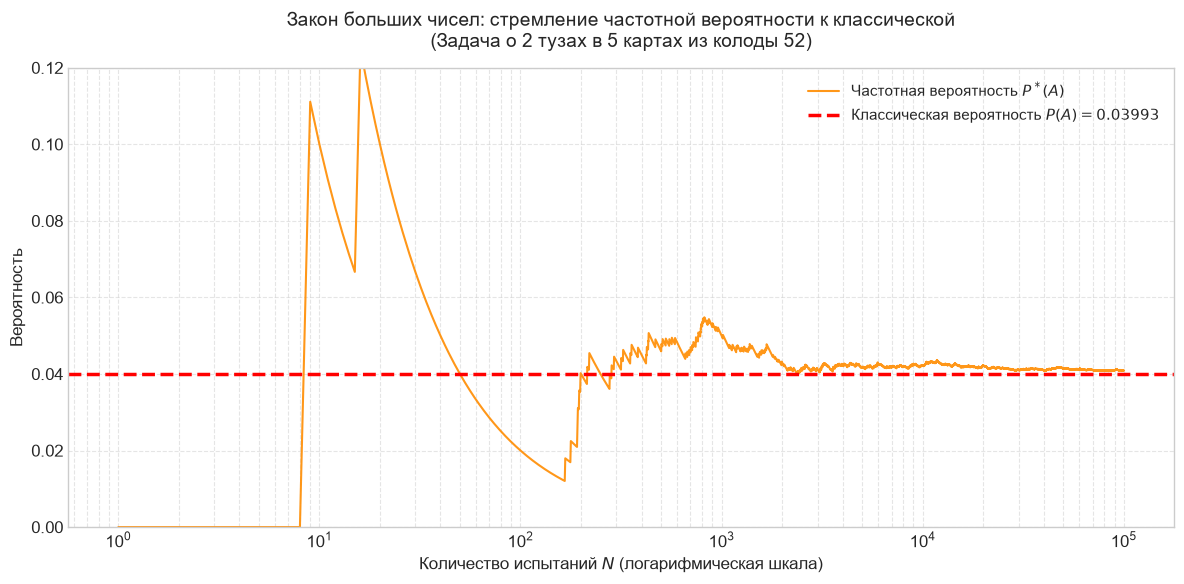

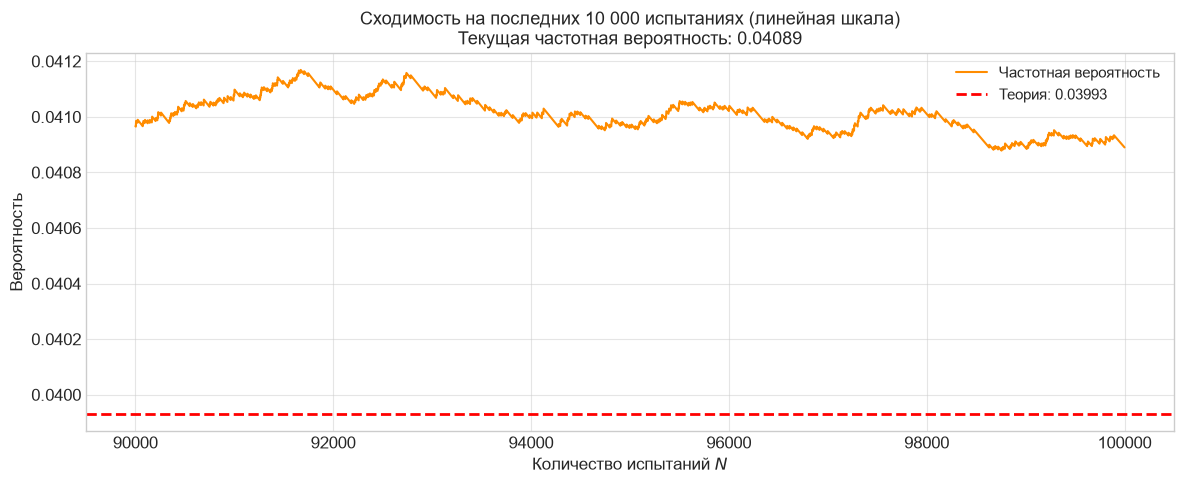

СТАТИСТИКА СХОДИМОСТИ
Теоретическая вероятность: 0.039930
Частотная вероятность (N=100,000): 0.040890
Относительная погрешность: 2.40%

Значения на ключевых точках:
  N=   100: P* = 0.020000 (отклонение: 0.019930)
  N= 1,000: P* = 0.050000 (отклонение: 0.010070)
  N=10,000: P* = 0.042200 (отклонение: 0.002270)
  N=50,000: P* = 0.041540 (отклонение: 0.001610)
  N=100,000: P* = 0.040890 (отклонение: 0.000960)


In [10]:
# График 1: Логарифмическая шкала (полный диапазон)
plt.figure(figsize=(12, 6))

plt.plot(N_values, empirical_probs, 
         label='Частотная вероятность $P^*(A)$', 
         color='darkorange', linewidth=1.5, alpha=0.9)

plt.axhline(p_classic, color='red', linestyle='--', linewidth=2.5, 
            label=f'Классическая вероятность $P(A) = {p_classic:.5f}$')

plt.xscale('log')
plt.ylim(0, 0.12)
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.title('Закон больших чисел: стремление частотной вероятности к классической\n'
          '(Задача о 2 тузах в 5 картах из колоды 52)', fontsize=14, pad=15)
plt.xlabel('Количество испытаний $N$ (логарифмическая шкала)', fontsize=12)
plt.ylabel('Вероятность', fontsize=12)
plt.legend(loc='upper right', fontsize=11, framealpha=0.9)

plt.tight_layout()
plt.show()

# График 2: Линейная шкала (последние 10000 испытаний для детального просмотра)
plt.figure(figsize=(12, 5))

tail_start = N_max - 10000
tail_N = N_values[tail_start:]
tail_P = empirical_probs[tail_start:]

plt.plot(tail_N, tail_P, color='darkorange', linewidth=1.5, label='Частотная вероятность')
plt.axhline(p_classic, color='red', linestyle='--', linewidth=2, 
            label=f'Теория: {p_classic:.5f}')

plt.xlabel('Количество испытаний $N$', fontsize=12)
plt.ylabel('Вероятность', fontsize=12)
plt.title(f'Сходимость на последних 10 000 испытаниях (линейная шкала)\n'
          f'Текущая частотная вероятность: {empirical_probs[-1]:.5f}', fontsize=13)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

# Вывод статистики

print(f"СТАТИСТИКА СХОДИМОСТИ")

print(f"Теоретическая вероятность: {p_classic:.6f}")
print(f"Частотная вероятность (N={N_max:,}): {empirical_probs[-1]:.6f}")
print(f"Относительная погрешность: {abs(empirical_probs[-1] - p_classic)/p_classic*100:.2f}%")
print(f"\nЗначения на ключевых точках:")
for n_check in [100, 1000, 10000, 50000, 100000]:
    idx = n_check - 1
    print(f"  N={n_check:>6,}: P* = {empirical_probs[idx]:.6f} (отклонение: {abs(empirical_probs[idx] - p_classic):.6f})")